In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import math
import gc
import os
import sys
import functools
os.environ["HF_HOME"] = "/cs/student/project_msc/2025/csml/katayama/huggingface_cache/stage1_step1413814"
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datasets import load_dataset
import itertools
from tqdm.std import tqdm
import glob
import re
import numpy as np
from sklearn.decomposition import IncrementalPCA
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

In [2]:
# Import custom module
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

%load_ext autoreload
%autoreload 2

from modules.experiment_helpers import set_seed

In [3]:
model_id = "allenai/OLMo-3-1025-7B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
subject = "all"
batch_size = 2
Trained = True
Parameter_Obtained = False
set_seed(42)

cuda


In [4]:
if not Trained:
    print(f"loading {model_id}...")
    tokenizer = AutoTokenizer.from_pretrained(model_id, revision = "stage1-step1413814")
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4"
    )

    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        dtype=torch.bfloat16,
        device_map="auto",
        revision = "stage1-step1413814", 
        quantization_config=quantization_config
    )
    model.eval()

In [5]:
if not Trained: 
    print(f"loading MMLU ({subject})...")
    dataset = load_dataset("cais/mmlu", subject, split="test")

In [6]:
if not Trained: 
    choices = ["A", "B", "C", "D"]
    choice_ids = [tokenizer.encode(c, add_special_tokens=False)[-1] for c in choices]
    prompt_template = "Question: {question}\nA. {a}\nB. {b}\nC. {c}\nD. {d}\nAnswer: "

In [7]:
if not Trained:
    prompts = []
    answers = []
    categories = [] 
    
    for sample in dataset:
        p = prompt_template.format(
            question=sample['question'],
            a=sample['choices'][0],
            b=sample['choices'][1],
            c=sample['choices'][2],
            d=sample['choices'][3]
        )
        prompts.append(p)
        answers.append(sample['answer'])
        categories.append(sample['subject'])

    correct_count = 0
    total_count = len(dataset)

In [8]:
save_dir = "Result/olmo_chunks_stage1-step1413814"
os.makedirs(save_dir, exist_ok=True)

if not Trained:
    tokenizer.padding_side = 'left'
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    target_layers_list = [0, 7, 15, 23, 31]
    num_heads = model.config.num_attention_heads
    head_dim = model.config.hidden_size // num_heads

    activation_cache = {}
    correct_count = 0
    total_count = len(dataset)

    def get_attention_pre_hook(layer_idx, module, input):
        x = input[0] 
        batch_size, seq_len, _ = x.shape
        head_outputs = x.view(batch_size, seq_len, num_heads, head_dim)
        head_l2_norms = torch.norm(head_outputs, p=2, dim=-1)
        activation_cache[layer_idx] = head_l2_norms

    handles = []
    for layer_idx in target_layers_list:
        hook_fn = functools.partial(get_attention_pre_hook, layer_idx)
        handle = model.model.layers[layer_idx].self_attn.o_proj.register_forward_pre_hook(hook_fn)
        handles.append(handle)

    group1_S_dict = {layer: [] for layer in target_layers_list}
    group2_S_dict = {layer: [] for layer in target_layers_list}
    group1_T_list = []
    group2_T_list = []
    
    group1_labels_list = []
    group2_labels_list = []

    print("="*50)
    print(f"Starting feature extraction & evaluation loop...")
    print("="*50)

    chunk_size = 50 
    batch_counter = 0
    chunk_idx = 0
    total_batches = math.ceil(total_count / batch_size)


    for i in range(0, total_count, batch_size):
        current_batch = i // batch_size
        
        # 50 batches
        if current_batch % chunk_size == 0:
            print(f"Processing batch {current_batch}/{total_batches} (Chunk {chunk_idx})...")

        batch_prompts = prompts[i:i+batch_size]
        batch_answers = answers[i:i+batch_size]
        
        if not batch_prompts: continue

        inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True, truncation=True, max_length=1024)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        prompt_lengths = inputs['attention_mask'].sum(dim=1)

        try:
            with torch.inference_mode():
                gen_outputs = model.generate(
                    **inputs,
                    max_new_tokens=10, 
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id
                )
            
            handles = []
            for layer_idx in target_layers_list:
                hook_fn = functools.partial(get_attention_pre_hook, layer_idx)
                handle = model.model.layers[layer_idx].self_attn.o_proj.register_forward_pre_hook(hook_fn)
                handles.append(handle)

            activation_cache.clear()
            full_attention_mask = (gen_outputs != tokenizer.pad_token_id).long()
            
            with torch.inference_mode():
                model(gen_outputs, attention_mask=full_attention_mask, output_hidden_states=False)
                all_token_embeddings = model.get_input_embeddings()(gen_outputs)

            max_prompt_len = inputs['input_ids'].shape[1] 

            for j in range(len(batch_prompts)):
                p_len = prompt_lengths[j].item() 
                gen_len = (gen_outputs[j] != tokenizer.pad_token_id).sum().item() - p_len
                
                if gen_len <= 0: continue
                    
                prompt_start = max_prompt_len - p_len
                prompt_end = max_prompt_len
                gen_end = max_prompt_len + gen_len
                
                cat = categories[i + j] 

                # [Group 2]
                T_g2 = all_token_embeddings[j, prompt_start+1:prompt_end, :].detach().cpu()
                group2_T_list.append(T_g2)
                group2_labels_list.extend([cat] * T_g2.shape[0]) 
                
                for layer_idx in target_layers_list:
                    S_g2 = activation_cache[layer_idx][j, prompt_start:prompt_end-1, :].detach().cpu()
                    group2_S_dict[layer_idx].append(S_g2)

                # [Group 1]
                T_g1 = all_token_embeddings[j, prompt_end:gen_end, :].detach().cpu()
                group1_T_list.append(T_g1)
                group1_labels_list.extend([cat] * T_g1.shape[0]) 
                
                for layer_idx in target_layers_list:
                    S_g1 = activation_cache[layer_idx][j, prompt_end-1:gen_end-1, :].detach().cpu()
                    group1_S_dict[layer_idx].append(S_g1)

            for handle in handles:
                handle.remove()

            batch_counter += 1
            if batch_counter >= chunk_size:
                torch.save(torch.cat(group1_T_list, dim=0), f"{save_dir}/T_g1_chunk_{chunk_idx}.pt")
                torch.save(torch.cat(group2_T_list, dim=0), f"{save_dir}/T_g2_chunk_{chunk_idx}.pt")
                
                torch.save(group1_labels_list, f"{save_dir}/Labels_g1_chunk_{chunk_idx}.pt")
                torch.save(group2_labels_list, f"{save_dir}/Labels_g2_chunk_{chunk_idx}.pt")
                
                group1_T_list.clear()
                group2_T_list.clear()
                group1_labels_list.clear() 
                group2_labels_list.clear() 

                for layer in target_layers_list:
                    torch.save(torch.cat(group1_S_dict[layer], dim=0), f"{save_dir}/S_g1_layer{layer}_chunk_{chunk_idx}.pt")
                    torch.save(torch.cat(group2_S_dict[layer], dim=0), f"{save_dir}/S_g2_layer{layer}_chunk_{chunk_idx}.pt")
                    group1_S_dict[layer].clear()
                    group2_S_dict[layer].clear()

                chunk_idx += 1
                batch_counter = 0

        except torch.cuda.OutOfMemoryError:
            print(f"OOM Error at batch {current_batch}. Skipping...")
            for handle in handles: handle.remove()
            pass
        finally:
            activation_cache.clear()
            torch.cuda.empty_cache()
            gc.collect()

    if len(group1_T_list) > 0:
        torch.save(torch.cat(group1_T_list, dim=0), f"{save_dir}/T_g1_chunk_{chunk_idx}.pt")
        if len(group2_T_list) > 0:
            torch.save(torch.cat(group2_T_list, dim=0), f"{save_dir}/T_g2_chunk_{chunk_idx}.pt")
            
        torch.save(group1_labels_list, f"{save_dir}/Labels_g1_chunk_{chunk_idx}.pt")
        torch.save(group2_labels_list, f"{save_dir}/Labels_g2_chunk_{chunk_idx}.pt")

        group1_T_list.clear()
        group2_T_list.clear()
        group1_labels_list.clear()
        group2_labels_list.clear()

        for layer in target_layers_list:
            torch.save(torch.cat(group1_S_dict[layer], dim=0), f"{save_dir}/S_g1_layer{layer}_chunk_{chunk_idx}.pt")
            if len(group2_S_dict[layer]) > 0:
                torch.save(torch.cat(group2_S_dict[layer], dim=0), f"{save_dir}/S_g2_layer{layer}_chunk_{chunk_idx}.pt")
            group1_S_dict[layer].clear()
            group2_S_dict[layer].clear()

    print(f"\nExtraction & Saving complete.")

In [9]:
# ==========================================
# 1. Dimensionality reduction of T (PCA: 4096 -> 128)
# ==========================================
import glob
import re
import numpy as np
import torch
from sklearn.decomposition import IncrementalPCA

if not Parameter_Obtained: 
    print("Starting PCA dimensionality reduction (Incremental PCA version) for the target variable T...")
    reduced_dim = 128

    def get_chunk_idx(filename):
        match = re.search(r'chunk_(\d+)\.pt', filename)
        return int(match.group(1)) if match else -1

    g1_files = sorted(glob.glob(f"{save_dir}/T_g1_chunk_*.pt"), key=get_chunk_idx)
    g2_files = sorted(glob.glob(f"{save_dir}/T_g2_chunk_*.pt"), key=get_chunk_idx)

    ipca = IncrementalPCA(n_components=reduced_dim)

    # ==========================================
    # 2. Train PCA axes
    # ==========================================
    print("Training PCA axes (partial_fit)...")
    all_files = g1_files + g2_files

    buffer = []
    buffer_size = 0
    min_samples = 512

    for f in all_files:
        chunk_data = torch.load(f, map_location='cpu').to(torch.float32).numpy()

        if chunk_data.shape[0] > 1000:
            indices = np.random.choice(chunk_data.shape[0], size=1000, replace=False)
            chunk_data = chunk_data[indices]

        buffer.append(chunk_data)
        buffer_size += chunk_data.shape[0]

        if buffer_size >= min_samples:
            batch_data = np.vstack(buffer)
            ipca.partial_fit(batch_data)
            buffer = []
            buffer_size = 0
            del batch_data

    if len(buffer) > 0:
        batch_data = np.vstack(buffer)
        if batch_data.shape[0] >= reduced_dim:
            ipca.partial_fit(batch_data)
        del buffer
        del batch_data

    # ==========================================
    # 3. Projection of Group 1
    # ==========================================
    print("Projecting Group 1 data...")
    T_group1_pca_list = []
    for f in g1_files:
        chunk_data = torch.load(f, map_location='cpu').to(torch.float32).numpy()
        transformed = ipca.transform(chunk_data)
        T_group1_pca_list.append(torch.tensor(transformed, dtype=torch.float32))
        del chunk_data

    # ==========================================
    # 4. Projection of Group 2
    # ==========================================
    print("Projecting Group 2 data...")
    T_group2_pca_list = []
    for f in g2_files:
        chunk_data = torch.load(f, map_location='cpu').to(torch.float32).numpy()
        transformed = ipca.transform(chunk_data)
        T_group2_pca_list.append(torch.tensor(transformed, dtype=torch.float32))
        del chunk_data

    # ==========================================
    # 5. Concatenation and L2 normalization
    # ==========================================
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    T_group1_pca = torch.cat(T_group1_pca_list, dim=0)
    T_group2_pca = torch.cat(T_group2_pca_list, dim=0)

    print(f"PCA complete: Reduced dimensionality is {T_group1_pca.shape[1]}")

    print("Restoring the concatenation of S (L2 norm) data...")

    target_layers_list = [0, 7, 15, 23, 31]
    final_S_group1 = {}
    final_S_group2 = {}

    for layer in target_layers_list:
        s_g1_files = sorted(glob.glob(f"{save_dir}/S_g1_layer{layer}_chunk_*.pt"), key=get_chunk_idx)
        s_g1_tensors = [torch.load(f, map_location='cpu').to(torch.float32) for f in s_g1_files]
        final_S_group1[layer] = torch.cat(s_g1_tensors, dim=0)

        s_g2_files = sorted(glob.glob(f"{save_dir}/S_g2_layer{layer}_chunk_*.pt"), key=get_chunk_idx)
        s_g2_tensors = [torch.load(f, map_location='cpu').to(torch.float32) for f in s_g2_files]
        final_S_group2[layer] = torch.cat(s_g2_tensors, dim=0)

    print("S data concatenation completed")

    # ==========================================
    # 6. Restore Category Labels
    # ==========================================
    print("Restoring category labels...")
    final_labels_group1 = []
    l_g1_files = sorted(glob.glob(f"{save_dir}/Labels_g1_chunk_*.pt"), key=get_chunk_idx)
    for f in l_g1_files:
        final_labels_group1.extend(torch.load(f))
    final_labels_group1 = np.array(final_labels_group1)
    
    final_labels_group2 = []
    l_g2_files = sorted(glob.glob(f"{save_dir}/Labels_g2_chunk_*.pt"), key=get_chunk_idx)
    for f in l_g2_files:
        final_labels_group2.extend(torch.load(f))
    final_labels_group2 = np.array(final_labels_group2)
    print(f"Labels restored successfully. (G1: {len(final_labels_group1)}, G2: {len(final_labels_group2)})")

Starting PCA dimensionality reduction (Incremental PCA version) for the target variable T...
Training PCA axes (partial_fit)...


Projecting Group 1 data...


Projecting Group 2 data...


PCA complete: Reduced dimensionality is 128
Restoring the concatenation of S (L2 norm) data...


S data concatenation completed
Restoring category labels...


Labels restored successfully. (G1: 140420, G2: 1498019)


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_save_path = "Result/publish/LLM/olmo/stage1-step1413814_bootstrap.pt"

# ==========================================
# 1. Model Definitions
# ==========================================
class GaussianSynergyModel(nn.Module):
    def __init__(self, num_heads, target_dim, k):
        super().__init__()
        self.k = k
        self.combo_indices = {}
        self.thetas = nn.ParameterDict()
        self.theta_T = nn.Parameter(torch.zeros(target_dim))
        
        for i in range(1, k + 1):
            combos = torch.combinations(torch.arange(num_heads), r=i)
            self.combo_indices[str(i)] = combos
            init_scale = 0.01 / math.sqrt(combos.shape[0])
            self.thetas[str(i)] = nn.Parameter(torch.randn(combos.shape[0], target_dim) * init_scale)

    def forward(self, S):
        mu = self.theta_T.unsqueeze(0).expand(S.shape[0], -1)
        if self.k == 0:
            return mu
        for i in range(1, self.k + 1):
            combos = self.combo_indices[str(i)].to(S.device)
            theta_i = self.thetas[str(i)]
            S_prod = torch.prod(S[:, combos], dim=2)
            mu_i = torch.matmul(S_prod, theta_i) / combos.shape[0]
            mu = mu + mu_i
        return mu

class TrueTotalSynergyMLP(nn.Module):
    def __init__(self, num_heads, target_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_heads, 512),
            nn.GELU(),
            nn.Linear(512, 512),
            nn.GELU(),
            nn.Linear(512, target_dim)
        )

    def forward(self, S):
        return self.net(S)

# ==========================================
# 2. Stratified Bootstrap Function
# ==========================================
def stratified_bootstrap_indices(labels, sample_limit):
    unique_labels, counts = np.unique(labels, return_counts=True)
    ratios = counts / len(labels)
    
    boot_indices = []
    for label, ratio in zip(unique_labels, ratios):
        label_limit = int(sample_limit * ratio)
        label_indices = np.where(labels == label)[0]
        if len(label_indices) > 0:
            sampled = np.random.choice(label_indices, size=label_limit, replace=True)
            boot_indices.extend(sampled)
            
    while len(boot_indices) < sample_limit:
        boot_indices.append(np.random.choice(len(labels)))
        
    boot_indices = np.array(boot_indices)
    np.random.shuffle(boot_indices)
    return boot_indices[:sample_limit]

# ==========================================
# 3. Calculation Function
# ==========================================
def calculate_all_kl_and_total_mi(S_tensor, T_tensor, max_k=5, epochs=100, n_splits=3, batch_size=1024):
    target_dim = T_tensor.shape[1]
    num_heads = S_tensor.shape[1]
    total_samples = S_tensor.shape[0]
    
    lr_candidates = [1e-4, 1e-3]
    wd_candidates = [0.0, 1e-4, 1e-2]
    
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    kl_results = {0: 0.0}
    total_mi = 0.0
    val_mse_results = {}
    
    models_k0_per_fold = []
    sigma2_k0_per_fold = []
    prev_models_per_fold = []
    prev_sigma2_per_fold = []
    
    steps = list(range(max_k + 1)) + ['Total_MI']
    
    for step in steps:
        best_val_mse = float('inf')
        best_params = (lr_candidates[0], wd_candidates[0])
        best_models = []
        
        for lr, wd in itertools.product(lr_candidates, wd_candidates):
            val_mse_list = []
            current_temp_models = []
            
            for train_idx, val_idx in kf.split(X=np.zeros(total_samples)):
                S_train, T_train = S_tensor[train_idx], T_tensor[train_idx]
                S_val, T_val = S_tensor[val_idx], T_tensor[val_idx]
                
                if step == 'Total_MI':
                    model = TrueTotalSynergyMLP(num_heads, target_dim).to(S_tensor.device)
                else:
                    model = GaussianSynergyModel(num_heads, target_dim, step).to(S_tensor.device)
                    
                optimizer = optim.Adam(model.parameters(), lr=lr)
                
                for _ in range(epochs):
                    indices = torch.randperm(S_train.shape[0])
                    for start_idx in range(0, S_train.shape[0], batch_size):
                        b_idx = indices[start_idx:start_idx + batch_size]
                        S_b, T_b = S_train[b_idx], T_train[b_idx]
                        
                        optimizer.zero_grad()
                        mse_loss = F.mse_loss(model(S_b), T_b)
                        l1_penalty = sum(torch.sum(torch.abs(param)) for param in model.parameters())
                        loss = mse_loss + wd * l1_penalty
                        loss.backward()
                        optimizer.step()
                        
                with torch.no_grad():
                    val_mse_sum = 0.0
                    for start_idx in range(0, S_val.shape[0], batch_size):
                        S_b = S_val[start_idx:start_idx + batch_size]
                        T_b = T_val[start_idx:start_idx + batch_size]
                        val_mse_sum += F.mse_loss(model(S_b), T_b, reduction='sum').item()
                    val_mse = val_mse_sum / (S_val.shape[0] * target_dim)
                    val_mse_list.append(val_mse)
                
                current_temp_models.append(model)
                
            avg_val_mse = sum(val_mse_list) / n_splits
            if avg_val_mse < best_val_mse:
                best_val_mse = avg_val_mse
                best_params = (lr, wd)
                best_models = current_temp_models
                
        val_mse_results[step] = best_val_mse
        current_models_per_fold = best_models
            
        if step == 0:
            models_k0_per_fold = current_models_per_fold
            prev_models_per_fold = current_models_per_fold
            
            fold_idx = 0
            for train_idx, val_idx in kf.split(X=np.zeros(total_samples)):
                S_val, T_val = S_tensor[val_idx], T_tensor[val_idx]
                model_0 = current_models_per_fold[fold_idx]
                
                with torch.no_grad():
                    mse_0_sum = sum(F.mse_loss(model_0(S_val[start_idx:start_idx+batch_size]), T_val[start_idx:start_idx+batch_size], reduction='sum').item() for start_idx in range(0, S_val.shape[0], batch_size))
                    sigma2_0 = max(mse_0_sum / (S_val.shape[0] * target_dim), 1e-8)
                    sigma2_k0_per_fold.append(sigma2_0)
                    prev_sigma2_per_fold.append(sigma2_0)
                fold_idx += 1
            continue
            
        fold_kl_list = []
        current_sigma2_per_fold = []
        fold_idx = 0
        
        for train_idx, val_idx in kf.split(X=np.zeros(total_samples)):
            S_val, T_val = S_tensor[val_idx], T_tensor[val_idx]
            model_current = current_models_per_fold[fold_idx]
            
            if step == 'Total_MI':
                model_base = models_k0_per_fold[fold_idx]
                base_sigma2 = sigma2_k0_per_fold[fold_idx]
            else:
                model_base = prev_models_per_fold[fold_idx]
                base_sigma2 = prev_sigma2_per_fold[fold_idx]
            
            with torch.no_grad():
                mse_mu_sum, curr_mse_sum = 0.0, 0.0
                for start_idx in range(0, S_val.shape[0], batch_size):
                    S_b, T_b = S_val[start_idx:start_idx+batch_size], T_val[start_idx:start_idx+batch_size]
                    mu_curr, mu_base = model_current(S_b), model_base(S_b)
                    mse_mu_sum += F.mse_loss(mu_curr, mu_base, reduction='sum').item()
                    curr_mse_sum += F.mse_loss(mu_curr, T_b, reduction='sum').item()
                
                mse_mu = mse_mu_sum / (S_val.shape[0] * target_dim)
                curr_sigma2 = max(curr_mse_sum / (S_val.shape[0] * target_dim), 1e-8)
                
                term1 = (curr_sigma2 / base_sigma2) - 1.0 - math.log(curr_sigma2 / base_sigma2)
                fold_kl = (target_dim / 2.0) * (term1 + (mse_mu / base_sigma2))
                fold_kl_list.append(max(0.0, fold_kl))
                current_sigma2_per_fold.append(curr_sigma2)
                
            fold_idx += 1
            
        kl_val = sum(fold_kl_list) / n_splits
        
        if step == 'Total_MI':
            total_mi = kl_val
        else:
            kl_results[step] = kl_results[step-1] + kl_val
            prev_models_per_fold = current_models_per_fold
            prev_sigma2_per_fold = current_sigma2_per_fold

    return kl_results, total_mi, val_mse_results


In [11]:
if not Parameter_Obtained:
    # ==========================================
    # 4. Bootstrap Evaluation Loop (Progressive Save & Resume)
    # ==========================================
    n_boot = 25 
    epochs_val = 300 
    sample_limit = 10000 
    max_eval_k = 5

    print("\n" + "="*60)
    print(f"[Bootstrap Analysis] Starting stratified bootstrap (Total Target: n={n_boot}, epochs={epochs_val})")
    print("="*60)

    if os.path.exists(data_save_path):
        print(f"Existing save file found at '{data_save_path}'. Loading progress...")
        saved_boot_dict = torch.load(data_save_path)
        boot_data_g1 = saved_boot_dict['boot_data_g1']
        boot_data_g2 = saved_boot_dict['boot_data_g2']
        target_layers_list = saved_boot_dict['target_layers']
        completed_boots = len(boot_data_g1[1][target_layers_list[0]])
        print(f"-> Resuming from iteration {completed_boots + 1}...")
    else:
        boot_data_g1 = {k: {layer: [] for layer in target_layers_list} for k in list(range(1, max_eval_k + 1)) + ['total_mi']}
        boot_data_g2 = {k: {layer: [] for layer in target_layers_list} for k in list(range(1, max_eval_k + 1)) + ['total_mi']}
        completed_boots = 0
        print("-> Starting a fresh run...")

    if completed_boots >= n_boot:
        print(f"Target of {n_boot} iterations is already completed!")
    
    for b in range(completed_boots, n_boot):
        print(f"\n>>> Running Bootstrap Iteration {b + 1} / {n_boot} ...")
        
        idx_g1 = stratified_bootstrap_indices(final_labels_group1, sample_limit)
        idx_g2 = stratified_bootstrap_indices(final_labels_group2, sample_limit)
        
        for layer in target_layers_list:
            print(f"    - Layer L{layer+1} Processing...")
            
            # --- Group 1 ---
            S_g1_b = final_S_group1[layer][idx_g1].to(device).float()
            T_g1_b = T_group1_pca[idx_g1].to(device).float()
            kl_res_g1, total_mi_g1, _ = calculate_all_kl_and_total_mi(
                S_g1_b, T_g1_b, max_k=max_eval_k, epochs=epochs_val, n_splits=3)
            
            boot_data_g1['total_mi'][layer].append(total_mi_g1)
            for k in range(1, max_eval_k + 1):
                step_kl = max(0.0, kl_res_g1[k] - kl_res_g1[k-1])
                boot_data_g1[k][layer].append(step_kl)

            # --- Group 2 ---
            S_g2_b = final_S_group2[layer][idx_g2].to(device).float()
            T_g2_b = T_group2_pca[idx_g2].to(device).float()
            kl_res_g2, total_mi_g2, _ = calculate_all_kl_and_total_mi(
                S_g2_b, T_g2_b, max_k=max_eval_k, epochs=epochs_val, n_splits=3)
            
            boot_data_g2['total_mi'][layer].append(total_mi_g2)
            for k in range(1, max_eval_k + 1):
                step_kl = max(0.0, kl_res_g2[k] - kl_res_g2[k-1])
                boot_data_g2[k][layer].append(step_kl)

        saved_boot_dict = {
            'target_layers': target_layers_list,
            'boot_data_g1': boot_data_g1,
            'boot_data_g2': boot_data_g2
        }
        os.makedirs(os.path.dirname(data_save_path), exist_ok=True)
        torch.save(saved_boot_dict, data_save_path)
        print(f"    [SAVED] Progress up to iteration {b + 1} has been safely saved.")

    print(f"\nAll {n_boot} Bootstrap iterations completed successfully.")

else:
    if os.path.exists(data_save_path):
        saved_boot_dict = torch.load(data_save_path)
        target_layers_list = saved_boot_dict['target_layers']
        boot_data_g1 = saved_boot_dict['boot_data_g1']
        boot_data_g2 = saved_boot_dict['boot_data_g2']
        completed_boots = len(boot_data_g1[1][target_layers_list[0]])
        print(f"Bootstrap data loaded (Completed iterations: {completed_boots}).")


[Bootstrap Analysis] Starting stratified bootstrap (Total Target: n=25, epochs=300)
Existing save file found at 'Result/publish/LLM/olmo/stage1-step1413814_bootstrap.pt'. Loading progress...
-> Resuming from iteration 17...

>>> Running Bootstrap Iteration 17 / 25 ...


    - Layer L1 Processing...


    - Layer L8 Processing...


    - Layer L16 Processing...


    - Layer L24 Processing...


    - Layer L32 Processing...


... (45 outputs left out)

    - Layer L16 Processing...


    - Layer L24 Processing...


    - Layer L32 Processing...


    [SAVED] Progress up to iteration 25 has been safely saved.

All 25 Bootstrap iterations completed successfully.



Generating line plots with 95% Confidence Intervals...


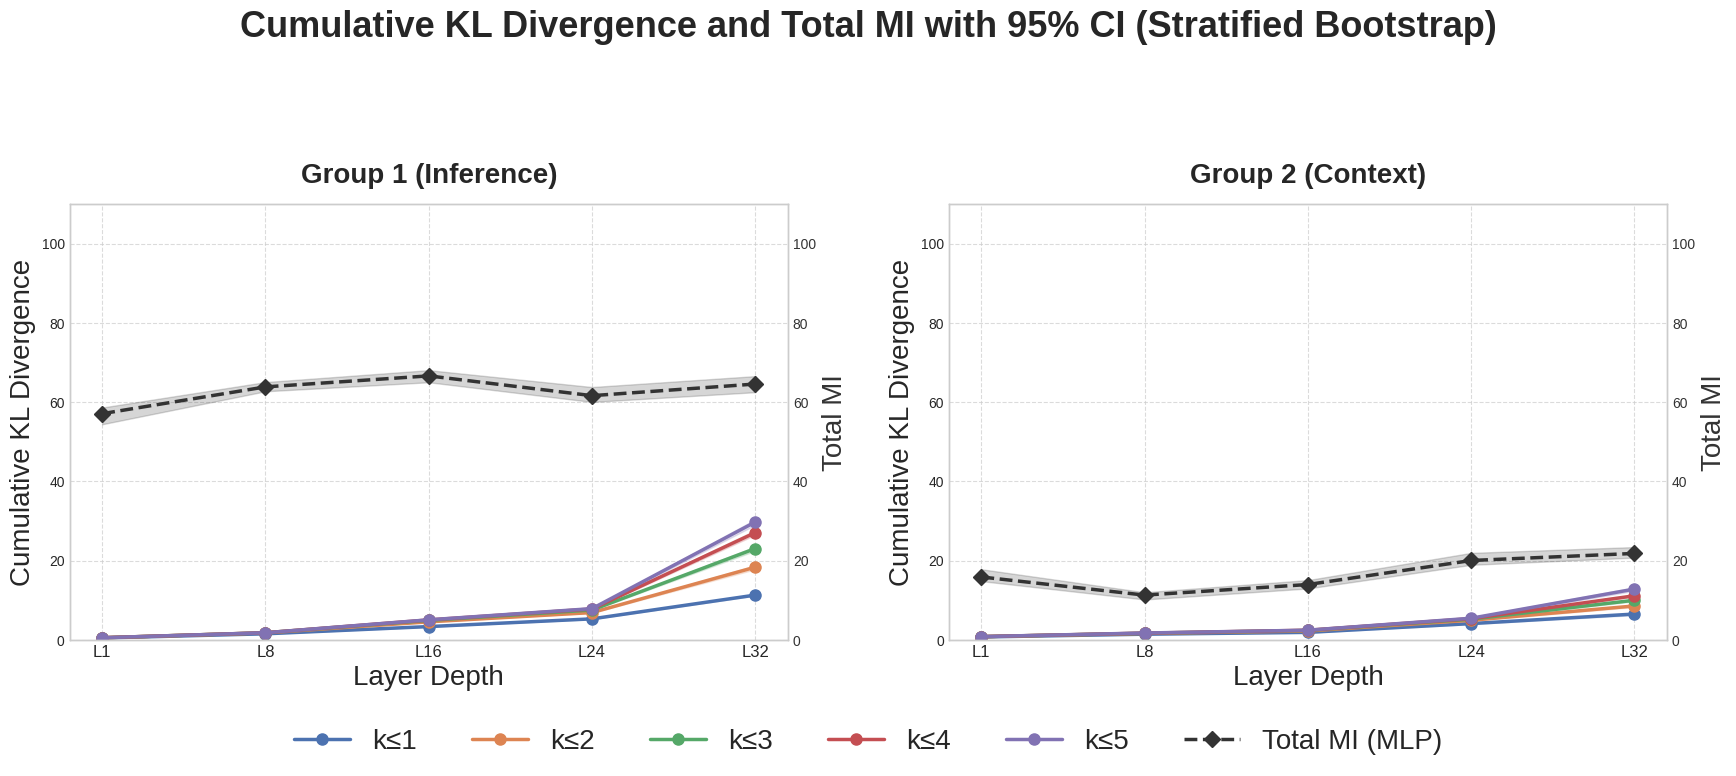

Plotting complete. Saved to 'Result/publish/plot/LLM/olmo/kl_trends/stage1-step1413814_bootstrap_ci.png'.


In [12]:
# ==========================================
# 5. Plot Cumulative KL Divergence with 95% CI
# ==========================================
print("\n" + "="*60)
print(f"Generating line plots with 95% Confidence Intervals...")
print("="*60)

FIXED_MAX_KL = 110 
FIXED_MAX_MI = 110 

plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

fig.suptitle("Cumulative KL Divergence and Total MI with 95% CI (Stratified Bootstrap)", 
             fontsize=26, fontweight='bold', y=1.05)

x_positions = np.arange(len(target_layers_list))
layer_labels = [f"L{l+1}" for l in target_layers_list]
colors = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b3']
total_color = '#333333'

def plot_boot_trends_cumulative_fixed(ax_left, boot_dict, title):
    n_boot = len(boot_dict[1][target_layers_list[0]])
    cumulative_boot_vals = np.zeros((n_boot, len(target_layers_list)))
    
    for k in range(1, 6):
        step_vals = np.array([boot_dict[k][l] for l in target_layers_list]).T
        cumulative_boot_vals += step_vals
        
        mean_vals = np.mean(cumulative_boot_vals, axis=0)
        lower_vals = np.percentile(cumulative_boot_vals, 2.5, axis=0)
        upper_vals = np.percentile(cumulative_boot_vals, 97.5, axis=0)
        
        ax_left.plot(x_positions, mean_vals, marker='o', linewidth=2.5, markersize=8, color=colors[k-1], label=f'k≤{k}')
        ax_left.fill_between(x_positions, lower_vals, upper_vals, color=colors[k-1], alpha=0.2)
        
    ax_left.set_xlabel('Layer Depth', fontsize=20)
    ax_left.set_ylabel('Cumulative KL Divergence', fontsize=20)
    ax_left.set_xticks(x_positions)
    ax_left.set_xticklabels(layer_labels, fontsize=12)
    ax_left.grid(True, linestyle='--', alpha=0.7)
    ax_left.set_ylim(0, FIXED_MAX_KL)

    ax_right = ax_left.twinx()
    mi_vals = np.array([boot_dict['total_mi'][l] for l in target_layers_list]).T 
    
    mean_mi = np.mean(mi_vals, axis=0)
    lower_mi = np.percentile(mi_vals, 2.5, axis=0)
    upper_mi = np.percentile(mi_vals, 97.5, axis=0)
    
    ax_right.plot(x_positions, mean_mi, marker='D', linestyle='--', linewidth=2.5, markersize=8, color=total_color, label='Total MI (MLP)')
    ax_right.fill_between(x_positions, lower_mi, upper_mi, color=total_color, alpha=0.2)
    
    ax_right.set_ylabel('Total MI', fontsize=20, color=total_color)
    ax_right.tick_params(axis='y', labelcolor=total_color)
    ax_right.grid(False) 
    ax_right.set_ylim(0, FIXED_MAX_MI)
    ax_left.set_title(title, fontsize=20, fontweight='bold', pad=15)
    
    return ax_right

ax1_right = plot_boot_trends_cumulative_fixed(ax1, boot_data_g1, 'Group 1 (Inference)')
ax2_right = plot_boot_trends_cumulative_fixed(ax2, boot_data_g2, 'Group 2 (Context)')

handles_left, labels_left = ax1.get_legend_handles_labels()
handles_right, labels_right = ax1_right.get_legend_handles_labels()
fig.legend(handles_left + handles_right, labels_left + labels_right, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=6, fontsize=20)

plt.tight_layout(pad=3.0)
fig.subplots_adjust(bottom=0.15)
trend_save_path = "Result/publish/plot/LLM/olmo/kl_trends/stage1-step1413814_bootstrap_ci.png"
os.makedirs(os.path.dirname(trend_save_path), exist_ok=True)
plt.savefig(trend_save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Plotting complete. Saved to '{trend_save_path}'.")